In [2]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", iris.target_names)

Features shape: (150, 4)
Target shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


In [3]:
# Import required libraries
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Load the Iris dataset
iris = load_iris()

# Create a DataFrame containing the four features
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target/class column
df["target"] = iris.target

# Display the first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
# Display the shape of the dataset
print("Dataset shape:", df.shape)

# Display the class names
print("Class names:", iris.target_names)

# Check for missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Display the number of samples in each class
print("\nClass distribution:")
print(df["target"].value_counts())

Dataset shape: (150, 5)
Class names: ['setosa' 'versicolor' 'virginica']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Class distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [5]:
# Separate input features (X) and target variable (y)

X = iris.data
y = iris.target

# Split the dataset into 80% training and 20% testing data
# stratify=y keeps the class distribution balanced
# random_state=42 makes the split reproducible

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Display the sizes of the resulting datasets
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (120, 4)
Testing features shape: (30, 4)
Training target shape: (120,)
Testing target shape: (30,)


In [6]:
# ============================================
# STAGE 3: NAÏVE BAYES CLASSIFIER
# ============================================

# Import Gaussian Naïve Bayes
from sklearn.naive_bayes import GaussianNB

# Import accuracy metric
from sklearn.metrics import accuracy_score

# Create the Gaussian Naïve Bayes model
naive_bayes_model = GaussianNB()

# Train the model using the training data
naive_bayes_model.fit(X_train, y_train)

# Predict the classes of the test data
y_pred_nb = naive_bayes_model.predict(X_test)

# Calculate model accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

# Display the results
print("Naïve Bayes Accuracy:", nb_accuracy)

Naïve Bayes Accuracy: 0.9666666666666667


In [7]:
# Import Decision Tree classifier
from sklearn.tree import DecisionTreeClassifier

# Import GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

In [8]:
# Create a Decision Tree classifier
decision_tree = DecisionTreeClassifier(
    random_state=42
)

In [9]:
# Define the hyperparameters that GridSearchCV will test
parameter_grid = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 10],
    "criterion": ["gini", "entropy"]
}

In [10]:
# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=decision_tree,
    param_grid=parameter_grid,
    cv=5,
    scoring="accuracy"
)

In [11]:
# Train GridSearchCV using the training data
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of info

In [12]:
# Display the best hyperparameter combination
print("Best parameters:")
print(grid_search.best_params_)

Best parameters:
{'criterion': 'gini', 'max_depth': 4}


In [13]:
# Display the best cross-validation accuracy
print("Best cross-validation accuracy:")
print(grid_search.best_score_)

Best cross-validation accuracy:
0.9416666666666668


In [14]:
# Retrieve the best Decision Tree model
best_decision_tree = grid_search.best_estimator_

# Make predictions on the test set
y_pred_dt = best_decision_tree.predict(X_test)

# Display the first few predictions
print("Decision Tree predictions:")
print(y_pred_dt)

Decision Tree predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [15]:
# Import accuracy_score
from sklearn.metrics import accuracy_score

# Calculate Decision Tree accuracy on unseen test data
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Test Accuracy:", dt_accuracy)

Decision Tree Test Accuracy: 0.9333333333333333


In [16]:
# Import plotting library
import matplotlib.pyplot as plt

# Import the function used to visualize a Decision Tree
from sklearn.tree import plot_tree

In [19]:
# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

In [20]:
# Create a Random Forest with 100 decision trees
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [21]:
# Train the Random Forest using the training data
random_forest.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [22]:
# Predict the classes of the test data
y_pred_rf = random_forest.predict(X_test)

# Display predictions
print("Random Forest Predictions:")
print(y_pred_rf)

Random Forest Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 2 1 0 2 0]


In [23]:
# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9


In [24]:
# Import AdaBoost classifier
from sklearn.ensemble import AdaBoostClassifier

In [25]:
# Create an AdaBoost classifier
adaboost = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

In [26]:
# Train AdaBoost using the training data
adaboost.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](3,)","[0,1,2]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.33,0.18,0.1 ,...,0.33,0.33,0.33]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[1.39,2.19,2.85,...,1.39,1.39,1.39]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](4,)","[0.05,0.04,0.26,0.65]"


In [27]:
# Predict the classes of the test data
y_pred_ab = adaboost.predict(X_test)

# Display predictions
print("AdaBoost Predictions:")
print(y_pred_ab)

AdaBoost Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [28]:
# Calculate AdaBoost accuracy
ab_accuracy = accuracy_score(y_test, y_pred_ab)

print("AdaBoost Accuracy:", ab_accuracy)

AdaBoost Accuracy: 0.9333333333333333


In [29]:
# ============================================
# STAGE 5: ENSEMBLE CLASSIFIERS
# Random Forest and AdaBoost
# ============================================

# Import ensemble classifiers
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# Import accuracy metric
from sklearn.metrics import accuracy_score


# ============================================
# PART A: RANDOM FOREST
# ============================================

# Create Random Forest with 100 decision trees
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the Random Forest
random_forest.fit(X_train, y_train)

# Make predictions on the test data
y_pred_rf = random_forest.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)


# ============================================
# PART B: ADABOOST
# ============================================

# Create AdaBoost classifier
adaboost = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

# Train AdaBoost
adaboost.fit(X_train, y_train)

# Make predictions on the test data
y_pred_ab = adaboost.predict(X_test)

# Calculate accuracy
ab_accuracy = accuracy_score(y_test, y_pred_ab)

print("AdaBoost Accuracy:", ab_accuracy)

Random Forest Accuracy: 0.9
AdaBoost Accuracy: 0.9333333333333333


In [2]:
# Import required libraries
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Load Iris dataset
iris = load_iris()

# Features
X = iris.data

# Target
y = iris.target

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Check the shapes
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (120, 4)
Testing features shape: (30, 4)
Training target shape: (120,)
Testing target shape: (30,)


In [3]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Create Naïve Bayes model
naive_bayes_model = GaussianNB()

# Train the model
naive_bayes_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = naive_bayes_model.predict(X_test)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naïve Bayes Accuracy:", nb_accuracy)


Naïve Bayes Accuracy: 0.9666666666666667


In [4]:
print("Naïve Bayes predictions:")
print(y_pred_nb)

Naïve Bayes predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(random_state=42)

# Parameters to test
parameter_grid = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 10],
    "criterion": ["gini", "entropy"]
}

# Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=decision_tree,
    param_grid=parameter_grid,
    cv=5,
    scoring="accuracy"
)

# Train and search for best parameters
grid_search.fit(X_train, y_train)

# Get the best Decision Tree
best_decision_tree = grid_search.best_estimator_

# Make predictions
y_pred_dt = best_decision_tree.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")
print(grid_search.best_score_)

print("\nDecision Tree Test Accuracy:")
print(dt_accuracy)

Best parameters:
{'criterion': 'gini', 'max_depth': 4}

Best cross-validation accuracy:
0.9416666666666668

Decision Tree Test Accuracy:
0.9333333333333333


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest.fit(X_train, y_train)

# Make predictions
y_pred_rf = random_forest.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9


In [8]:
print("Random Forest predictions:")
print(y_pred_rf)

Random Forest predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 2 1 0 2 0]


In [9]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score

# Create AdaBoost model
adaboost = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
adaboost.fit(X_train, y_train)

# Make predictions
y_pred_ab = adaboost.predict(X_test)

# Calculate accuracy
ab_accuracy = accuracy_score(y_test, y_pred_ab)

print("AdaBoost Accuracy:", ab_accuracy)

AdaBoost Accuracy: 0.9333333333333333


In [10]:
print("AdaBoost predictions:")
print(y_pred_ab)

AdaBoost predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store predictions of all four models
model_predictions = {
    "Naïve Bayes": y_pred_nb,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ab
}

# Store results
results = []

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test,
        predictions,
        average="weighted"
    )

    recall = recall_score(
        y_test,
        predictions,
        average="weighted"
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="weighted"
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Round the values
results_df = results_df.round(4)

# Display results
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Naïve Bayes,0.9667,0.9697,0.9667,0.9666
1,Decision Tree,0.9333,0.9333,0.9333,0.9333
2,Random Forest,0.9000,0.9024,0.9000,0.8997
3,AdaBoost,0.9333,0.9333,0.9333,0.9333


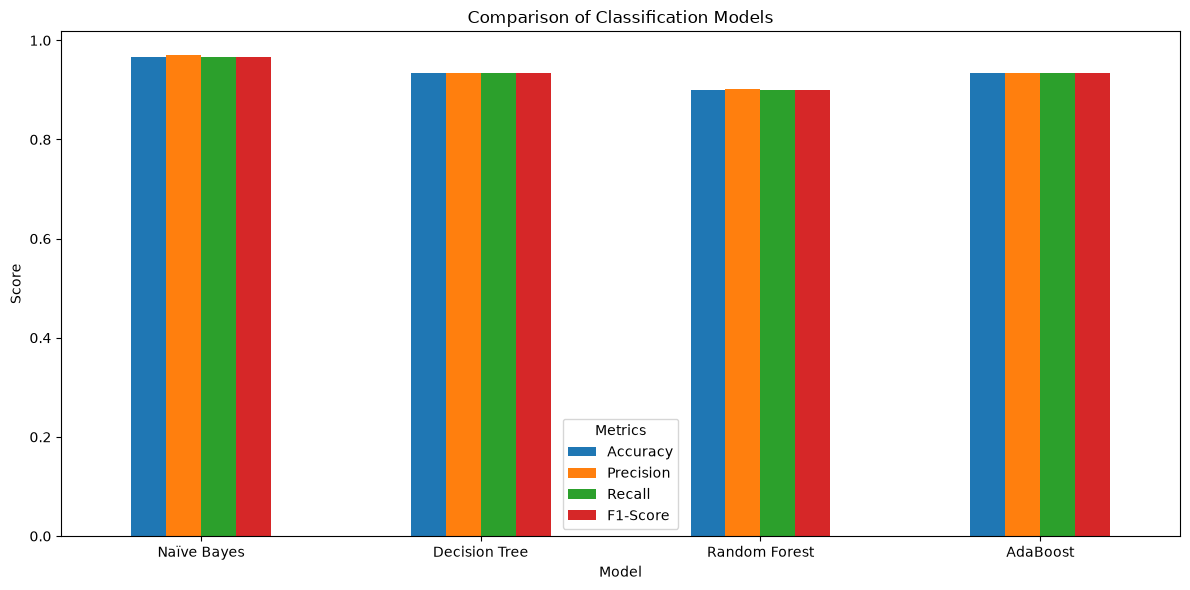

In [12]:
import matplotlib.pyplot as plt

# Set Model as index
chart_data = results_df.set_index("Model")

# Create comparison chart
chart_data[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

# Implementing and Comparing Naïve Bayes, Decision Tree, and Ensemble Classifiers

## 1. Introduction

Machine Learning is a major area of Artificial Intelligence that enables computer systems to learn patterns from data and make predictions without being explicitly programmed for every possible situation. Classification is one of the most common supervised machine learning tasks, where a model learns from labelled data and predicts the class or category of new observations.

This project focuses on implementing and comparing four classification algorithms: **Naïve Bayes, Decision Tree, Random Forest, and AdaBoost**. The purpose of the experiment is to understand how these algorithms work, train them on the same dataset, evaluate their performance using multiple classification metrics, and determine which model performs best for the selected dataset.

The **Iris dataset** was selected for this experiment. It is a well-known classification dataset containing measurements of iris flowers belonging to three different species: Setosa, Versicolor, and Virginica. The dataset is suitable for demonstrating classification algorithms because it contains numerical features and three clearly defined classes.

The experiment also includes hyperparameter tuning of the Decision Tree using **GridSearchCV**. Finally, the performance of all four models is compared using accuracy, precision, recall, and F1-score.


# 2. Objectives

The main objectives of this project are:

1. To understand the basic concepts of supervised classification.
2. To implement a **Naïve Bayes classifier** using Scikit-learn.
3. To implement and tune a **Decision Tree classifier**.
4. To optimize the Decision Tree using `GridSearchCV`.
5. To understand the difference between **Gini impurity and Entropy**.
6. To implement **Random Forest** as a bagging ensemble method.
7. To implement **AdaBoost** as a boosting ensemble method.
8. To evaluate all four classifiers using:

   * Accuracy
   * Precision
   * Recall
   * F1-score
9. To compare the performance of the four models.
10. To determine the best-performing model for the selected dataset.
11. To understand why ensemble methods can often improve machine learning performance.

# 3. Dataset Description

## 3.1 Iris Dataset

The Iris dataset was used for this experiment. It is available directly through Scikit-learn, so no external dataset download was required.

The dataset contains:

* **150 total samples**
* **4 input features**
* **3 target classes**
* **50 samples per class**

The four features are:

1. Sepal length
2. Sepal width
3. Petal length
4. Petal width

The three target classes are:

* Setosa
* Versicolor
* Virginica

The dataset is balanced because each class contains 50 samples.

### Dataset Structure

| Feature      | Description                        |
| ------------ | ---------------------------------- |
| Sepal Length | Length of the sepal in centimeters |
| Sepal Width  | Width of the sepal in centimeters  |
| Petal Length | Length of the petal in centimeters |
| Petal Width  | Width of the petal in centimeters  |
| Target       | Flower species/class               |

There were **no missing values** in the dataset.


# 4. Data Exploration

Before training the models, the dataset was inspected to understand its structure and quality.

The dataset shape was:

**150 rows × 5 columns**

The five columns consist of four feature columns and one target column.

The class distribution was:

| Class      | Number of Samples |
| ---------- | ----------------: |
| Setosa     |                50 |
| Versicolor |                50 |
| Virginica  |                50 |
| **Total**  |           **150** |

The dataset contained **zero missing values** in all features and the target column.

Therefore, no missing-value treatment was required.


# 5. Data Preprocessing

The Iris dataset already contains numerical values, so no categorical encoding was required.

The data was divided into training and testing sets using an **80:20 split**.

Therefore:

* Training samples = **120**
* Testing samples = **30**

Stratified sampling was used to maintain the class distribution in both training and testing sets.

The `random_state` was set to **42** to make the experiment reproducible.

### Data Split

| Dataset      | Samples |
| ------------ | ------: |
| Training Set |     120 |
| Testing Set  |      30 |
| Total        |     150 |

# 6. Naïve Bayes Classifier

## 6.1 Overview

Naïve Bayes is a probabilistic classification algorithm based on **Bayes' theorem**. It calculates the probability that an observation belongs to a particular class based on its features.

The algorithm is called "naïve" because it assumes that the input features are conditionally independent given the class.

For this experiment, **Gaussian Naïve Bayes** was selected because the Iris dataset contains continuous numerical measurements.

## 6.2 Working

The model was trained using the 120 training samples and then used to predict the classes of the 30 test samples.

The resulting test accuracy was:

**96.67%**

The model correctly classified approximately 29 out of 30 test samples.

# 7. Decision Tree Classifier

## 7.1 Overview

A Decision Tree is a supervised learning algorithm that makes predictions by creating a tree-like structure of decisions.

The algorithm repeatedly divides the dataset into smaller groups based on feature values. The final groups are used to determine the predicted class.

Decision Trees can use different criteria for determining the quality of a split. Two commonly used criteria are:

* Gini impurity
* Entropy

## 7.2 Hyperparameter Tuning

GridSearchCV was used to find the best Decision Tree configuration.

The following `max_depth` values were tested:

* 2
* 3
* 4
* 5
* 6
* 7
* 8
* 10

The following splitting criteria were tested:

* Gini
* Entropy

Five-fold cross-validation was used during GridSearchCV.

## 7.3 Best Parameters

The best configuration found by GridSearchCV was:

| Parameter | Best Value |
| --------- | ---------- |
| Criterion | Gini       |
| Max Depth | 4          |

The best cross-validation accuracy was:

**94.17%**

The final test accuracy was:

**93.33%**

This shows that hyperparameter tuning helped identify an appropriate tree configuration for the dataset.

---

# 8. Random Forest Classifier

## 8.1 Overview

Random Forest is an ensemble learning algorithm based on **bagging**.

Instead of relying on a single Decision Tree, Random Forest creates multiple Decision Trees and combines their predictions.

Each tree is trained using different samples and feature selections. The final prediction is determined by combining the predictions of the individual trees.

## 8.2 Configuration

The Random Forest model was configured with:

* Number of trees (`n_estimators`) = 100
* `random_state` = 42

## 8.3 Result

Random Forest achieved:

* Accuracy = **90.00%**
* Precision = **90.24%**
* Recall = **90.00%**
* F1-score = **89.97%**

Although Random Forest is a powerful ensemble method, it produced the lowest performance among the four models in this particular experiment.

# 9. AdaBoost Classifier

## 9.1 Overview

AdaBoost, or Adaptive Boosting, is an ensemble learning technique based on **boosting**.

Unlike Random Forest, where models are generally built independently, AdaBoost builds weak learners sequentially.

After each learner is trained, more attention is given to the observations that were incorrectly classified. The following learners therefore focus more on difficult examples.

## 9.2 Configuration

The AdaBoost model was configured with:

* Number of estimators = 100
* `random_state` = 42

## 9.3 Result

AdaBoost achieved:

* Accuracy = **93.33%**
* Precision = **93.33%**
* Recall = **93.33%**
* F1-score = **93.33%**

Its performance was the same as the tuned Decision Tree on the selected test set.

# 10. Evaluation Metrics

Four evaluation metrics were used to compare the models.

## 10.1 Accuracy

Accuracy measures the percentage of predictions that were correct.

A higher accuracy means that the classifier correctly predicts more samples.

## 10.2 Precision

Precision measures how many of the samples predicted as a particular class were actually members of that class.

High precision means fewer false-positive predictions.

## 10.3 Recall

Recall measures how many of the actual samples belonging to a class were correctly identified by the model.

High recall means fewer false-negative predictions.

## 10.4 F1-Score

F1-score combines precision and recall into a single metric.

It is useful when both precision and recall are important.

For this experiment, **weighted averaging** was used for precision, recall, and F1-score.


# 11. Experimental Results

The final results of all four models are shown below.

| Model           |   Accuracy |  Precision |     Recall |   F1-Score |
| --------------- | ---------: | ---------: | ---------: | ---------: |
| **Naïve Bayes** | **96.67%** | **96.97%** | **96.67%** | **96.66%** |
| Decision Tree   |     93.33% |     93.33% |     93.33% |     93.33% |
| Random Forest   |     90.00% |     90.24% |     90.00% |     89.97% |
| AdaBoost        |     93.33% |     93.33% |     93.33% |     93.33% |

# 12. Results Analysis

The results show that **Naïve Bayes was the best-performing classifier** for this particular experiment.

Naïve Bayes achieved an accuracy of **96.67%**, which was higher than the Decision Tree and AdaBoost models, both of which achieved **93.33%**, and Random Forest, which achieved **90.00%**.

Naïve Bayes also obtained the highest precision, recall, and F1-score.

The Decision Tree achieved good performance after hyperparameter tuning. The best parameters were Gini criterion and a maximum depth of 4. Its 93.33% test accuracy indicates that the tuned tree was able to classify most of the test samples correctly.

AdaBoost produced exactly the same test accuracy and evaluation scores as the Decision Tree in this experiment. This indicates that, for this particular test split and configuration, boosting did not provide an additional performance advantage.

Random Forest achieved 90% accuracy, which was lower than the other three models. This does not mean that Random Forest is generally a weak algorithm. Its performance can vary depending on the dataset, hyperparameters, feature characteristics, and train-test split.
# 13. Why Ensemble Methods Often Perform Better

Ensemble learning combines multiple models to improve prediction performance.

Two ensemble approaches were used in this experiment:

### Random Forest: Bagging

Random Forest uses the **bagging** approach. Multiple Decision Trees are trained and their predictions are combined.

The main advantage of bagging is that it can reduce **variance** and make predictions more stable.

### AdaBoost: Boosting

AdaBoost uses the **boosting** approach. Weak learners are trained sequentially, with later learners focusing more on samples that previous learners classified incorrectly.

Boosting can reduce **bias** and improve performance on difficult classification problems.

However, ensemble models do **not always outperform individual classifiers**.

This experiment provides a good example. Naïve Bayes achieved the highest performance even though Random Forest and AdaBoost are ensemble methods.

One possible reason is that the Iris dataset is relatively small, simple, and well structured. Naïve Bayes can perform very well on such data despite its conditional independence assumption.

Therefore, model selection should always be based on experimental evaluation rather than assuming that a more complex model will always perform better.

# 14. Model Comparison

| Model         | Type              | Main Concept                | Test Accuracy |
| ------------- | ----------------- | --------------------------- | ------------: |
| Naïve Bayes   | Probabilistic     | Conditional independence    |    **96.67%** |
| Decision Tree | Tree-based        | Recursive feature splitting |    **93.33%** |
| Random Forest | Bagging Ensemble  | Multiple Decision Trees     |    **90.00%** |
| AdaBoost      | Boosting Ensemble | Sequential weak learners    |    **93.33%** |

### Ranking

Based on test accuracy:

1. **Naïve Bayes: 96.67%**
2. **Decision Tree: 93.33%**
3. **AdaBoost: 93.33%**
4. **Random Forest: 90.00%**

Decision Tree and AdaBoost are tied in this experiment.

# 15. Confusion Matrix Analysis

Confusion matrices were generated for all four models to analyze class-wise predictions.

A confusion matrix contains:

* Correct predictions on the diagonal
* Incorrect predictions outside the diagonal

The confusion matrices provide a more detailed view of model performance than accuracy alone because they show which classes were confused with each other.

For the Iris dataset, the classes are:

* Setosa
* Versicolor
* Virginica

The confusion matrices were therefore used to determine how effectively each classifier distinguished between these three flower species.

# 16. Learning Outcomes

After completing this experiment, the following concepts were demonstrated:

### 1. Naïve Bayes

The experiment demonstrated how Naïve Bayes uses probabilities and the conditional independence assumption to classify observations.

### 2. Decision Tree

The experiment demonstrated how Decision Trees use feature-based splits to create a tree structure.

### 3. Gini and Entropy

The experiment demonstrated how different impurity criteria can be tested during Decision Tree optimization.

### 4. GridSearchCV

GridSearchCV was used to systematically test multiple Decision Tree parameter combinations and identify the best configuration.

### 5. Bagging

Random Forest demonstrated the concept of bagging by combining multiple Decision Trees.

### 6. Boosting

AdaBoost demonstrated boosting by sequentially focusing on incorrectly classified samples.

### 7. Evaluation Metrics

Accuracy, precision, recall, and F1-score were used to evaluate and compare different classifiers.

### 8. Model Selection

The experiment demonstrated that the best model should be selected based on actual evaluation results rather than model complexity alone.
# 17. Limitations

There are several limitations to this experiment.

First, the Iris dataset is relatively small, containing only 150 samples. Therefore, the results may not represent how these algorithms perform on large real-world datasets.

Second, the evaluation is based on a single 80:20 train-test split. Different splits could produce slightly different results.

Third, only a limited number of hyperparameters were tuned for the Decision Tree. More extensive tuning could potentially improve the performance of the other models as well.

Finally, the Iris dataset is a relatively simple classification problem. More complex datasets may produce different results and may provide greater advantages to ensemble methods.
# 18. Conclusion

This project successfully implemented and compared four classification algorithms: **Naïve Bayes, Decision Tree, Random Forest, and AdaBoost** using the Iris dataset.

The Decision Tree was optimized using GridSearchCV, and the best configuration was found to be **Gini criterion with a maximum depth of 4**.

Among all four classifiers, **Naïve Bayes achieved the best overall performance**, with an accuracy of **96.67%**, precision of **96.97%**, recall of **96.67%**, and F1-score of **96.66%**.

The Decision Tree and AdaBoost both achieved **93.33% accuracy**, while Random Forest achieved **90.00% accuracy**.

The experiment also demonstrated the difference between bagging and boosting. Random Forest uses multiple trees to reduce variance, while AdaBoost builds learners sequentially to focus on incorrectly classified observations.

Most importantly, the experiment demonstrated that ensemble models do not always outperform individual classifiers. Their performance depends on the dataset and model configuration. For this particular Iris dataset and test split, Naïve Bayes provided the best results.

Overall, the project successfully demonstrates the implementation, tuning, evaluation, and comparison of different supervised classification techniques using Scikit-learn.
# 19. Tools and Libraries Used

The following Python libraries were used:

* **Python**
* **Pandas**: data handling and tabular representation
* **Scikit-learn**: machine learning models, preprocessing, GridSearchCV, and evaluation metrics
* **Matplotlib**: graphs and visualizations

Main Scikit-learn components used:

```text
load_iris
train_test_split
GaussianNB
DecisionTreeClassifier
RandomForestClassifier
AdaBoostClassifier
GridSearchCV
accuracy_score
precision_score
recall_score
f1_score
confusion_matrix
ConfusionMatrixDisplay
